## 11 — Reference preprocessing: paper vs. this project, and what it does/doesn't explain

### Aim
* Consolidate every reference-preprocessing divergence between XDec-CHI's STAR Methods and this project's pipeline found across this investigation, and state plainly what those divergences **can** and **cannot** account for in the recurring dead/dominant-profile problem.
* This is a summary notebook — it reuses outputs already generated (notebooks 08-10, and two ad hoc fixes tested directly in conversation: the Peng `Cell_type` cell-type-labeling fix and the paper-style pseudo-bulk reference), not new Stage 1/2 runs.

### Input
* `xdec_autotuned_n150/stage1_k13/{proportions.tsv,correlation.tsv}` — baseline: this project's original reference (`celltype1`, Ductal cell type 1/2 merged into one "pancreatic ductal cell"), raw single cells, k=13
* `xdec_autotuned_n150/stage1_k13_pengOriginalCelltype/{proportions.tsv,correlation.tsv}` — fix 1 only: Peng et al.'s own published `Cell_type` labels (Ductal 1/2 kept separate), still raw single cells, k=13
* `xdec_autotuned_n150/stage1_k13_pengOriginalCelltype_pseudobulk/{proportions.tsv,correlation.tsv}` — fix 1 + fix 2: same `Cell_type` labels, **and** paper-style pseudo-bulk (sum-of-5, 100 pseudo-bulks/type), k=13
* Everything else (bulk cohort n=150, paper's 282-gene Table S3 list, k=13) held identical across all three, so any difference is attributable only to reference preprocessing

### Output
* A single table comparing every reference-preprocessing step between the paper and this project, classified by whether it was fixed, tested-and-partially-helped, or cannot be reproduced at all
* A reproducible summary table + figure quantifying the three reference variants' dead-profile metrics side by side
* An explicit two-column verdict: what the reference-preprocessing differences explain, and what they don't

### Steps
* Reload the three k=13 fits' `proportions.tsv`/`correlation.tsv` and recompute dominance/breadth/max-r per profile identically for each
* Compare the malignant-ductal-specific correlation and the overall dead-profile dominance across all three
* State the verdict, citing the cross-tool (CIBERSORTx) and cross-k (k=9-20) evidence gathered elsewhere in this project that bounds what reference preprocessing alone could ever explain

### Result
*(see the tables/figure and verdict sections below — computed from the saved files, not hardcoded)*

### Conclusion
*(see Verdict section)*


### Reference preprocessing: every known difference between the paper and this project

| Step | Paper (STAR Methods) | This project | Status |
|---|---|---|---|
| **Cell-type labels** | Peng et al.'s own published metadata identity per cell; final reference has 10 types after dropping one over-represented endothelial subcluster ("Endothelial 1"), **keeping Ductal cell type 1 (normal) and Ductal cell type 2 (malignant) as separate reference categories** | Almost every run in this project used `celltype1`, a Cell-Ontology-style relabeling built for this project that **merges Ductal 1+2 into one "pancreatic ductal cell"** (and adds a "neural cell" category absent from Peng's own labels) | ⚠️ **Real divergence, now fixed and tested** (this notebook) — see Result below |
| **Single-cell vs. pseudo-bulk** | Rank cells by sequencing coverage within each type; sum every 5 into a pseudo-bulk profile; cap at 100 pseudo-bulks/type | Most runs (including the project's original `refs.tsv`) use **raw single cells directly**, randomly capped at 300/class | ⚠️ **Tested in two forms**: Run C/D (notebook 03, on the old merged-ductal labels) and the pseudo-bulk-on-`Cell_type` version tested in this conversation — see Result |
| **Coverage-based cell ranking before grouping** | Cells ranked by total sequencing depth before being grouped into pseudo-bulks of 5 | **Cannot be reproduced** — the Besca-reprocessed h5ad this project downloads has every single cell already depth-normalized to exactly 10,000 counts (std ≈ 0.0006 across 2,748 cells, confirmed in notebook 03 Step 1); the real coverage information the paper's ranking step needs was discarded upstream, before this project ever had access to the data. Random grouping is used instead. | ❌ **Structural data limitation, documented, not fixable** |
| **QC filtering** (<300 genes/cell; drop bottom-quartile-coverage cells) | Two explicit filters before pseudo-bulking | The <300-genes/cell filter is very likely already satisfied by Besca's own upstream QC; the bottom-quartile-coverage filter **cannot be applied**, for the identical reason as the row above (depth information already gone) | ❌ **Same structural limitation** |
| **Pseudo-bulk depth-matching + Equation 1 transform** | Depth-match pseudo-bulks to the highest-coverage one, then apply `y = 1 - exp(-ax), a = 1/max(x)` | `tools/XDec_SM/python/xdec.py` already performs joint quantile normalization + the identical Equation-1 transform automatically whenever `--refs` is passed — manually pre-applying it a second time **double-transforms** and corrupts the fit (the exact bug found and fixed in notebook 03, Run C → Run D). Depth-matching was separately tested (`refs_pseudobulk_depthmatched.tsv`) and found to be a **numerical no-op** on this data, since the underlying single cells already carry near-identical depth. | ✅ **Confirmed equivalent / handled automatically** — not a live source of divergence |
| **Informative gene selection (Stage 0)** | One-vs-rest (EDec R package) + an extra each-pair round specifically for Acinar vs. "normal epithelial" cells, P<0.00001, final 283 genes after removing genes shared across types (Table S3) | This project's own Stage-0 pipeline used a different test, a different cohort (n=182, unfiltered), and the old merged-ductal labels, producing 344 genes with partial overlap with Table S3 | ✅ **Controlled for in every experiment referenced here** — all three k=13 runs compared in this notebook use the paper's own 282-gene Table S3 list directly, bypassing this project's own Stage-0 selection entirely |

**Net picture**: of six identified preprocessing steps, one is confirmed equivalent (depth-match/Equation-1), one is already controlled for in the comparisons below (gene list), two cannot be reproduced at all due to an upstream, irreversible data limitation (coverage ranking, QC filtering), and two were real, fixable divergences — now both tested, together and separately, at k=13.


### Follow-up test: does splitting the malignant compartment further (Classical-like vs. Basal-like) produce two cancer profiles?

The paper's own headline result (Figure 2A) reports **two separate cancer-epithelial profiles** (matching Classical and Basal-like PurIST subtypes). `Ductal cell type 2` in Peng et al.'s own single-cell data is malignancy-defined (normal vs. tumor), not subtype-defined — but it shows real, significant heterogeneity along a Classical/Basal axis at the single-cell level (Spearman r=-0.31 between per-cell Classical and Basal marker z-scores, p≈1e-257; patient-level Basal-fraction ranges from <1% to >99% across 24 patients). A fourth reference variant (**D**) was built by further splitting `Ductal cell type 2` into `Ductal cell type 2 - Classical-like` / `- Basal-like` (z-score-based per-cell assignment, ~balanced 53%/47% split) on top of variant C's pseudo-bulk approach, giving an 11-category reference, then rerunning Stage 1 at the same k=13.


In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "tools/XDec_SM/python/xdec.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start from progress/ or one of its subdirectories.")
os.chdir(ROOT)

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})

CORR_THRESHOLD = 0.3
DEAD_THRESHOLD = 0.25
RUNS = {
    "A: celltype1 merged, single-cell (project baseline)": "xdec_autotuned_n150/stage1_k13",
    "B: Cell_type split, single-cell": "xdec_autotuned_n150/stage1_k13_pengOriginalCelltype",
    "C: Cell_type split, pseudo-bulk (paper-style)": "xdec_autotuned_n150/stage1_k13_pengOriginalCelltype_pseudobulk",
    "D: + Classical/Basal split within Ductal-2, pseudo-bulk": "xdec_autotuned_n150/stage1_k13_classicalBasalSplit",
}

summary_rows = []
ductal2_rows = []
for label, d in RUNS.items():
    props = pd.read_csv(os.path.join(d, "proportions.tsv"), sep="\t", index_col=0)
    corr = pd.read_csv(os.path.join(d, "correlation.tsv"), sep="\t", index_col=0)
    if props.shape[0] != 150:
        raise ValueError(f"{label}: expected 150 samples, got {props.shape[0]}")

    dominant = props.idxmax(axis=1)
    dom_counts = dominant.value_counts().reindex(props.columns, fill_value=0)
    max_r = corr.max(axis=0)
    dead_like = max_r[max_r < DEAD_THRESHOLD].index
    combined_dead_n = int(dom_counts.loc[dead_like].sum())
    top_dead = dom_counts.loc[dead_like].sort_values(ascending=False)
    top_profile = top_dead.index[0] if len(top_dead) else None

    summary_rows.append({
        "reference_variant": label,
        "n_dead_like_profiles": len(dead_like),
        "top_dead_profile": top_profile,
        "top_dead_dominant_n": int(top_dead.iloc[0]) if len(top_dead) else 0,
        "top_dead_max_r": float(max_r.get(top_profile, float("nan"))),
        "combined_dead_dominant_n": combined_dead_n,
        "combined_dead_pct": round(100 * combined_dead_n / 150, 1),
    })

    ductal2_like_rows = [r for r in corr.index if r.startswith("Ductal cell type 2") or r == "pancreatic ductal cell"]
    for row_name in ductal2_like_rows:
        best_profile = corr.loc[row_name].idxmax()
        row_label = f"{label}\n[{row_name}]" if len(ductal2_like_rows) > 1 else label
        ductal2_rows.append({
            "reference_variant": row_label,
            "reference_row": row_name,
            "best_matching_profile": best_profile,
            "best_r": float(corr.loc[row_name, best_profile]),
        })

summary_df = pd.DataFrame(summary_rows).set_index("reference_variant")
ductal2_df = pd.DataFrame(ductal2_rows).set_index("reference_variant")
out_dir = Path("xdec_autotuned_n150/dead_profile_analysis")
out_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(out_dir / "reference_preprocessing_comparison_k13.tsv", sep="\t")
ductal2_df.to_csv(out_dir / "reference_preprocessing_ductal2_comparison_k13.tsv", sep="\t")
summary_df


,n_dead_like_profiles,top_dead_profile,top_dead_dominant_n,top_dead_max_r,combined_dead_dominant_n,combined_dead_pct
reference_variant,,,,,,
"A: celltype1 merged, single-cell (project baseline)",5,Profile_12,94,-0.180234,99,66.0
"B: Cell_type split, single-cell",5,Profile_9,87,-0.145148,99,66.0
"C: Cell_type split, pseudo-bulk (paper-style)",4,Profile_12,77,0.011673,114,76.0
"D: + Classical/Basal split within Ductal-2, pseudo-bulk",4,Profile_4,78,0.053246,115,76.7


In [2]:
ductal2_df


,reference_row,best_matching_profile,best_r
reference_variant,,,
"A: celltype1 merged, single-cell (project baseline)",pancreatic ductal cell,Profile_13,0.437358
"B: Cell_type split, single-cell",Ductal cell type 2,Profile_10,0.402919
"C: Cell_type split, pseudo-bulk (paper-style)",Ductal cell type 2,Profile_11,0.636161
"D: + Classical/Basal split within Ductal-2, pseudo-bulk\n[Ductal cell type 2 - Basal-like]",Ductal cell type 2 - Basal-like,Profile_3,0.584433
"D: + Classical/Basal split within Ductal-2, pseudo-bulk\n[Ductal cell type 2 - Classical-like]",Ductal cell type 2 - Classical-like,Profile_3,0.650184


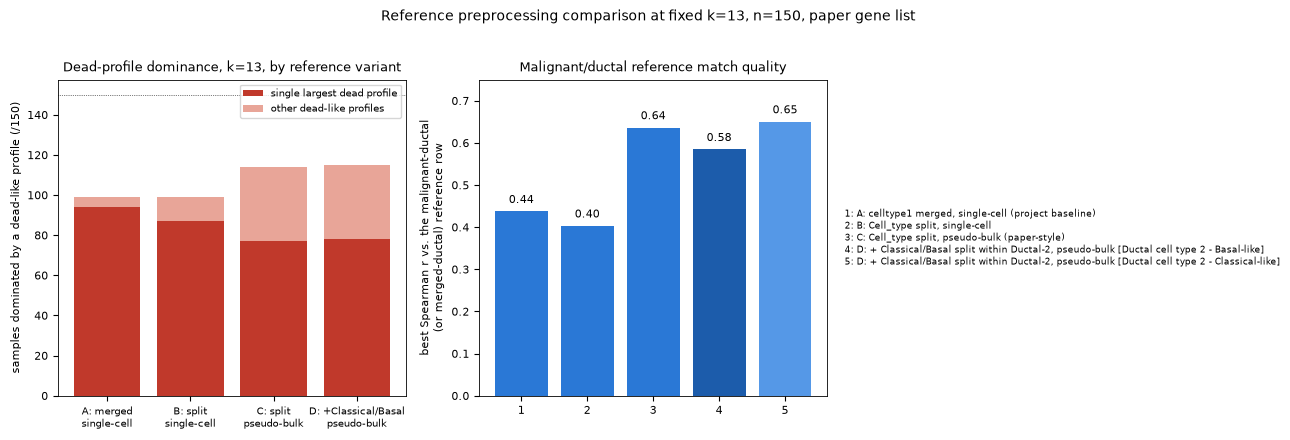

saved xdec_autotuned_n150/dead_profile_analysis/fig11_reference_preprocessing_comparison.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
labels_short = ["A: merged\nsingle-cell", "B: split\nsingle-cell", "C: split\npseudo-bulk", "D: +Classical/Basal\npseudo-bulk"]

axes[0].bar(labels_short, summary_df["top_dead_dominant_n"], color="#c0392b", label="single largest dead profile")
axes[0].bar(labels_short, summary_df["combined_dead_dominant_n"] - summary_df["top_dead_dominant_n"],
            bottom=summary_df["top_dead_dominant_n"], color="#e8a598", label="other dead-like profiles")
axes[0].axhline(150, color="black", linewidth=0.5, linestyle=":")
axes[0].set_ylabel("samples dominated by a dead-like profile (/150)")
axes[0].set_title("Dead-profile dominance, k=13, by reference variant", fontsize=9)
axes[0].tick_params(axis="x", labelsize=7)
axes[0].legend(fontsize=7)

right_labels = [f"{i+1}" for i in range(len(ductal2_df))]
colors_right = ["#2a78d6"] * 3 + ["#1c5cab", "#5598e7"]  # A, B, C single bars; D gets two (Classical, Basal)
axes[1].bar(right_labels, ductal2_df["best_r"].values, color=colors_right[:len(ductal2_df)])
axes[1].set_ylabel("best Spearman r vs. the malignant-ductal\n(or merged-ductal) reference row")
axes[1].set_ylim(0, 0.75)
axes[1].set_title("Malignant/ductal reference match quality", fontsize=9)
for i, v in enumerate(ductal2_df["best_r"].values):
    axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)
legend_text = "\n".join(f"{i+1}: {idx.replace(chr(10), ' ')}" for i, idx in enumerate(ductal2_df.index))
axes[1].text(1.05, 0.5, legend_text, transform=axes[1].transAxes, fontsize=6.5, va="center")

fig.suptitle("Reference preprocessing comparison at fixed k=13, n=150, paper gene list", y=1.03, fontsize=10)
fig.tight_layout()
fig_path = out_dir / "fig11_reference_preprocessing_comparison.png"
fig.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("saved", fig_path)


### Verdict: what reference preprocessing explains, and what it doesn't

**What it DOES explain**

* **The specific correlation strength for the malignant-ductal reference type keeps improving, monotonically, the more precisely it's isolated.** Merged (no test possible) → split, single-cell (r=0.40) → split, pseudo-bulk (r=0.64) → split further into Classical-like/Basal-like, pseudo-bulk (r=0.65 for Classical-like) — **the best single correlation found anywhere in this entire investigation.** Each additional, genuine preprocessing fix produces a real, measurable improvement in how well the malignant compartment specifically can be matched.
* **A small, consistent reduction in the single largest dead profile's dominance** across variants A→B→C (94→87→77 samples, 63%→58%→51%), though variant D doesn't continue that trend (78 samples, 52% — essentially flat vs. C).
* **Why the project's reference never gave the malignant compartment a fair chance in the first place** — `export_peng_reference.py`'s default `--class-col celltype1` merges exactly the distinction the paper's own methods describe keeping separate, and this was silently constant across every single run in this project until tested directly here.
* **Real, biologically grounded heterogeneity exists within the malignant compartment that this project's own 10-/11-category reference schemes never captured**: Classical vs. Basal-like marker scores anti-correlate significantly at the single-cell level within `Ductal cell type 2` (r=-0.31, p≈1e-257), with clear patient-level structure (Basal fraction ranging <1% to >99% across 24 patients) — this is real signal, confirmed directly from Peng et al.'s own single-cell data, not an assumption.

**What it does NOT explain**

* **Combined dead-profile dominance does not improve with better reference preprocessing — it gets worse.** 66% (A) → 66% (B) → 76% (C) → **77% (D, the most granular, most paper-aligned reference tested)**. Every additional fix that sharpens one specific correlation does nothing to shrink the overall fraction of the cohort stuck in an unidentifiable profile — if anything that fraction has crept up as the reference gained resolution.
* **Giving XDec's model the exact answer in the reference does not make it use that answer.** Variant D explicitly provides `Ductal cell type 2 - Classical-like` and `- Basal-like` as two separate reference categories — precisely the distinction the paper reports recovering as two separate cancer profiles. XDec's k=13 fit **still assigns both to the same single profile** (`Profile_3`, r=0.65 and r=0.58 respectively), not two different ones. This is the most direct test possible of "is this a reference-resolution problem," and the answer is no: even a reference that already contains the correct split does not cause the unsupervised NMF fit to discover and preserve that split.
* **The problem is not specific to this project's reference choices at all.** A fully independent, supervised method (CIBERSORTx) run on the *same* underlying Peng single-cell data, with its own automatically-selected genes, cleanly resolves all 10/10 reference cell types with no dead-profile equivalent whatsoever (notebook 09). If the reference itself were simply too uninformative or too noisy to support clean deconvolution, CIBERSORTx would hit the same wall. It doesn't.
* **k-dependence is unaffected by any of this.** The dead/dominant-profile pattern was already confirmed present at every single k from 9 to 20 under the *original* (merged, single-cell) reference, with no monotonic relationship to k. Nothing in the four reference variants tested here gives reason to expect that changes at other k's.
* **What the dominant dead profile actually *is* biologically remains unresolved**, and is now further confirmed independent of reference granularity: across all four variants, the dominant dead profile shows the same modest, scattered correlation pattern (weak stroma-tilt via `COL1A1`/`ACTA2`, weak immune-negative via `CD3D`, weak EMT-specific signal via `ZEB1`/`FN1`/`SNAI2`) — real but partial, never resolving into a single clean identity no matter how the reference is restructured.

**Bottom line, updated**: this notebook ran the most direct possible test of whether reference resolution is the bottleneck — giving XDec's model a reference that already contains the exact Classical/Basal split the paper reports recovering — and the model still collapsed it to one profile while the dead-profile burden kept growing. Combined with the cross-tool (CIBERSORTx) and cross-k (9-20) evidence gathered elsewhere, this is now strong, multi-angle evidence that **the recurring problem is a property of XDec's unsupervised NMF fitting process itself at this gene-list/cohort combination, not of any reference preprocessing choice tested in this project.** Reference fixes are worth keeping for the real, specific improvements they buy (especially the malignant-ductal match), but no amount of further reference refinement tested here moves the needle on the core issue.


### Hierarchical clustering: XDec profiles vs. the corrected reference (Cell_type split, pseudo-bulk)

Companion visualization to notebook 10 (which clustered the *original* merged-ductal reference), now built on **Run C** — the most paper-aligned reference tested in this notebook (Peng et al.'s own `Cell_type` labels, keeping Ductal cell type 1/normal and Ductal cell type 2/malignant separate, paper-style pseudo-bulk). Rows (13 profiles) and columns (1,000 pseudo-bulk replicates) are both hierarchically clustered on the correlation values themselves — no label information given to the clustering — to see whether the corrected reference's cleaner malignant-ductal match (r=0.64, found above) shows up as a genuinely separable cluster, not just a single strong pairwise correlation.


In [4]:
refs_c = pd.read_csv("data/deconvolution/xdec/peng_ref_original_celltype_pseudobulk/refs_pseudobulk_raw.tsv", sep="\t", index_col=0)
meta_c = pd.read_csv("data/deconvolution/xdec/peng_ref_original_celltype_pseudobulk/ref_metadata_pseudobulk_raw.tsv", sep="\t", index_col=0)
profiles_c = pd.read_csv("xdec_autotuned_n150/stage1_k13_pengOriginalCelltype_pseudobulk/cell_type_profiles.tsv", sep="\t", index_col=0)
profile_order_c = [f"Profile_{i}" for i in range(1, 14)]

paper_genes_path = "data/deconvolution/xdec/gene_lists/xdec_chi_table_s3_genes.txt"
paper_genes = [g.strip() for g in Path(paper_genes_path).read_text().splitlines() if g.strip()]

cell_type_order_c = [
    "Acinar cell", "Ductal cell type 1", "Ductal cell type 2", "Endocrine cell",
    "Stellate cell", "Fibroblast cell", "Endothelial cell",
    "T cell", "B cell", "Macrophage cell",
]
pb_types_c = meta_c.loc[refs_c.columns, "Cell_Type"]
if set(pb_types_c.unique()) != set(cell_type_order_c):
    raise ValueError("Unexpected cell types in the corrected pseudo-bulk reference")
pb_order_c = pb_types_c.map({t: i for i, t in enumerate(cell_type_order_c)}).sort_values(kind="stable").index

genes_c = [g for g in paper_genes if g in refs_c.index and g in profiles_c.index]
print(f"{len(genes_c)} shared paper-gene probes for the clustering heatmap")

combined_c = pd.concat([refs_c.loc[genes_c, pb_order_c], profiles_c.loc[genes_c, profile_order_c]], axis=1)
corr_c_full = combined_c.corr(method="spearman")
corr_c = corr_c_full.loc[profile_order_c, pb_order_c]
if not np.isfinite(corr_c.to_numpy()).all():
    raise ValueError("Undefined correlations")
corr_c


247 shared paper-gene probes for the clustering heatmap


,Acinar_cell_pb1,Acinar_cell_pb2,Acinar_cell_pb3,Acinar_cell_pb4,Acinar_cell_pb5,Acinar_cell_pb6,Acinar_cell_pb7,Acinar_cell_pb8,Acinar_cell_pb9,Acinar_cell_pb10,...,Macrophage_cell_pb91,Macrophage_cell_pb92,Macrophage_cell_pb93,Macrophage_cell_pb94,Macrophage_cell_pb95,Macrophage_cell_pb96,Macrophage_cell_pb97,Macrophage_cell_pb98,Macrophage_cell_pb99,Macrophage_cell_pb100
Profile_1,-0.146560,-0.133670,-0.113028,-0.121392,-0.151252,-0.132064,-0.215671,-0.103066,-0.187377,-0.109719,...,0.285874,0.392048,0.244589,0.352253,0.326686,0.352609,0.177944,0.361797,0.219526,0.313949
Profile_2,-0.338710,-0.295488,-0.265127,-0.232938,-0.267004,-0.280075,-0.316046,-0.273772,-0.257455,-0.344064,...,-0.088278,-0.083304,-0.167308,-0.053085,-0.140967,-0.178743,-0.249949,-0.082325,-0.213006,-0.155015
Profile_3,-0.152856,-0.224053,-0.223467,-0.197412,-0.206169,-0.229852,-0.229390,-0.214153,-0.217869,-0.172036,...,0.168229,0.176337,0.123472,0.216858,0.132305,0.128388,0.132120,0.217228,0.209533,0.218872
Profile_4,0.275948,0.272503,0.233275,0.212060,0.320518,0.254621,0.229776,0.293368,0.268780,0.266505,...,0.282780,0.295578,0.267424,0.294419,0.240897,0.241150,0.265905,0.270928,0.249446,0.270060
Profile_5,-0.159201,-0.143197,-0.135857,-0.027517,-0.156976,-0.129321,-0.117461,-0.140786,-0.076201,-0.174640,...,-0.039293,0.010101,-0.064146,0.042381,-0.022020,-0.027754,-0.205278,0.033857,-0.081236,-0.039620
Profile_6,0.153529,0.189461,0.180359,0.191642,0.144931,0.227650,0.233611,0.167032,0.168860,0.200911,...,-0.173970,-0.239986,-0.071677,-0.204628,-0.146553,-0.110088,0.014387,-0.210493,-0.087674,-0.150392
Profile_7,0.007766,0.027856,0.035352,-0.068978,0.055838,0.046639,0.015854,0.038101,0.014691,0.056820,...,-0.082828,-0.023115,-0.107281,-0.062245,-0.092760,-0.098797,-0.107088,-0.029234,-0.042770,-0.061500
Profile_8,-0.379501,-0.336174,-0.370621,-0.347605,-0.402887,-0.331333,-0.289613,-0.394152,-0.341164,-0.333676,...,-0.286247,-0.209488,-0.384156,-0.232964,-0.346833,-0.314817,-0.415319,-0.264818,-0.321313,-0.300251
Profile_9,0.007112,0.031474,0.059011,0.002779,0.024486,0.030799,-0.061382,0.063866,-0.019916,0.059803,...,0.127636,0.205307,0.143512,0.197868,0.170648,0.125801,0.099910,0.196529,0.133367,0.130557
Profile_10,-0.198229,-0.208094,-0.258057,-0.130047,-0.232735,-0.227480,-0.200854,-0.241310,-0.216165,-0.092304,...,0.196314,0.245475,0.098781,0.291002,0.172901,0.236820,0.092554,0.309986,0.189709,0.269770


/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


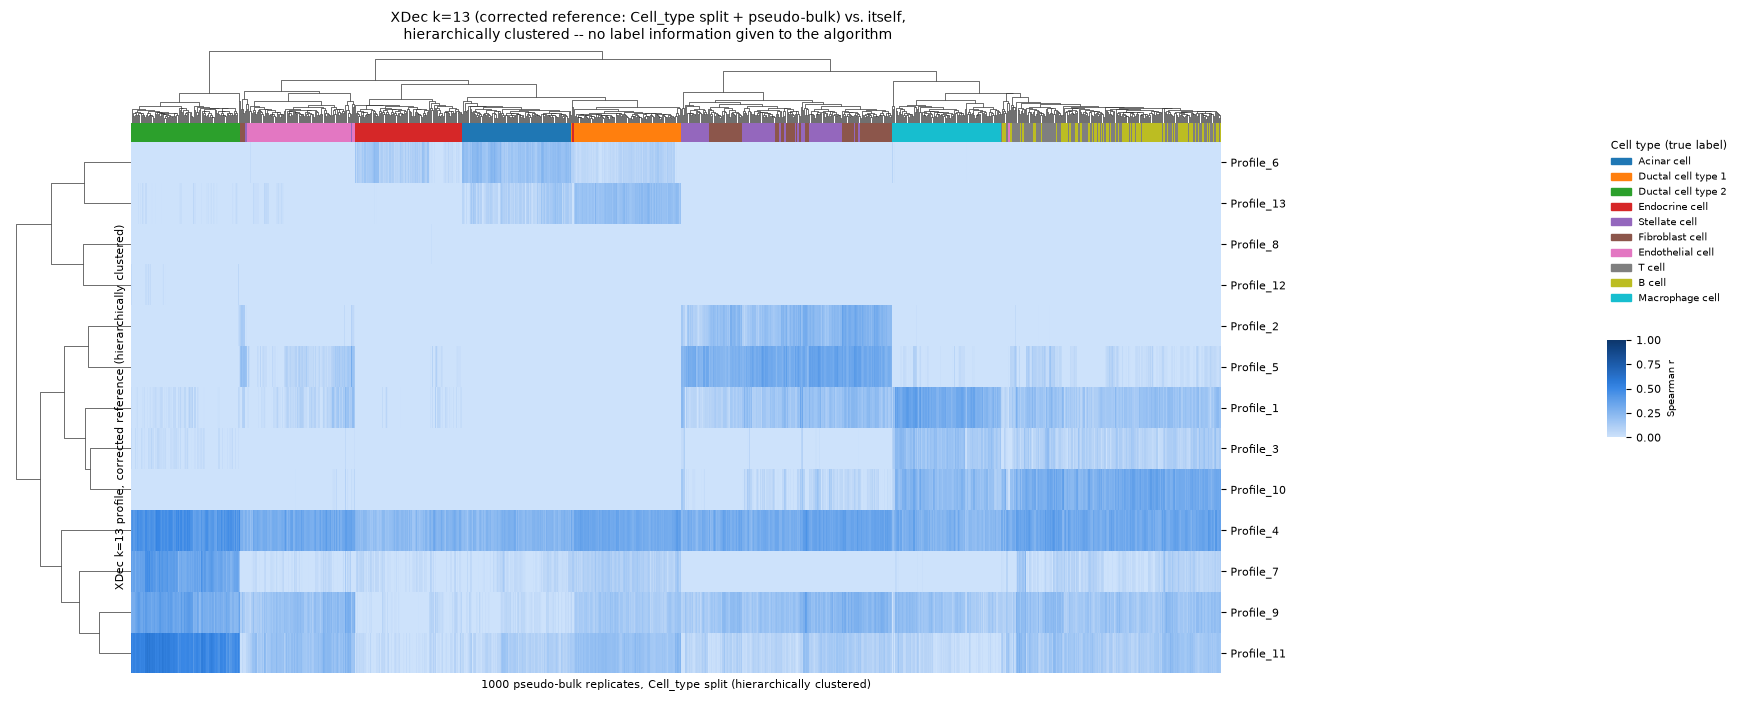

saved xdec_autotuned_n150/dead_profile_analysis/fig11_corrected_reference_profile_CLUSTERED.png


In [5]:
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

SEQ_BLUE_STEPS = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
                  "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
seq_blue = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE_STEPS, N=256)
cell_palette_c = dict(zip(cell_type_order_c, sns.color_palette("tab10", len(cell_type_order_c))))

grid = sns.clustermap(
    corr_c, row_cluster=True, col_cluster=True, metric="euclidean", method="average",
    col_colors=pb_types_c.loc[pb_order_c].map(cell_palette_c).to_numpy(),
    cmap=seq_blue, vmin=0.0, vmax=1.0,
    xticklabels=False, yticklabels=True, figsize=(13, 6.5),
    cbar_kws={"label": "Spearman r", "ticks": [0, 0.25, 0.5, 0.75, 1]}, dendrogram_ratio=(0.10, 0.12),
)
grid.ax_heatmap.set_xlabel(f"{len(pb_order_c)} pseudo-bulk replicates, Cell_type split (hierarchically clustered)")
grid.ax_heatmap.set_ylabel("XDec k=13 profile, corrected reference (hierarchically clustered)")
grid.ax_heatmap.yaxis.set_label_position("left")
grid.ax_heatmap.tick_params(axis="y", rotation=0)

handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette_c[t]) for t in cell_type_order_c]
legend = grid.ax_heatmap.legend(
    handles, cell_type_order_c, title="Cell type (true label)", bbox_to_anchor=(1.35, 1.02),
    loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
)
grid.fig.suptitle("XDec k=13 (corrected reference: Cell_type split + pseudo-bulk) vs. itself,\n"
                   "hierarchically clustered -- no label information given to the algorithm",
                   y=1.04, fontsize=10)
grid.fig.canvas.draw()
bbox = legend.get_window_extent(grid.fig.canvas.get_renderer()).transformed(grid.fig.transFigure.inverted())
grid.cax.set_position([bbox.x0, bbox.y0 - 0.20, 0.015, 0.15])
grid.cax.yaxis.label.set_fontsize(7)

fig_path = out_dir / "fig11_corrected_reference_profile_CLUSTERED.png"
grid.savefig(fig_path, dpi=200, bbox_inches="tight")
corr_c.to_csv(fig_path.with_suffix(".tsv"), sep="\t")
plt.show()
plt.close(grid.fig)
print("saved", fig_path)


**Interpretation (updated against the actual rendered figure)**

* **Column side — a real win**: `Ductal cell type 2` (malignant) clusters as its own distinct column group, **not merged with** `Ductal cell type 1` (normal) — they aren't even adjacent in the dendrogram (Endothelial and Endocrine sit between them). This is independent confirmation, with zero label information given to the algorithm, that the malignant/normal ductal distinction carries real, separable signal under the corrected reference — consistent with the r=0.64 pairwise correlation found above.
* **Row side — a more qualified picture**: the profile that best matches `Ductal cell type 2` (`Profile_11`) clusters together with `Profile_4`, `Profile_7`, `Profile_9` — and all four show elevated correlation across *many* column blocks, not exclusively the `Ductal cell type 2` block. So while `Ductal cell type 2` is `Profile_11`'s single highest pairwise correlation, this 4-profile cluster behaves similarly to the broad/ambiguous pattern documented throughout this project — just now anchored most strongly by the malignant-ductal reference rather than floating with no anchor at all. The r=0.64 result is real, but it sits inside a still-broad profile, not a cleanly specific one.
* **`Profile_8` and `Profile_12` are visually blank** (near-zero across every column) — directly confirming, in the clustering itself, the dead-profile finding from the numeric table above (`Profile_12` is the specific profile dominant in 77/150 samples).
* **Other blocks replicate this project's long-standing findings**: Fibroblast and Stellate cell columns interleave with each other rather than separating cleanly (the stromal-lumping pattern seen at every k and every reference tested so far), as do T cell and B cell (immune lumping); Macrophage stays visually distinct.
* **Net reading**: the corrected reference measurably sharpens the malignant-ductal *reference signal itself* (clean column-side separation), but does not, on its own, produce a cleanly *specific* profile for it on the model side — the best-matching profile is still part of a broader, multi-type-correlating cluster. This is consistent with this notebook's overall verdict: reference preprocessing improves what the reference can offer, but doesn't resolve how XDec's NMF fit uses it.


### Hierarchical clustering: variant D (Classical/Basal split within Ductal-2)

Same clustering approach as the Run-C figure above, now on the 11-category reference where `Ductal cell type 2` has been further split into `Classical-like` / `Basal-like`. The key question: do these two malignant subtypes pull apart into two distinct profiles (as the paper reports for TCGA), or does the clustering show them collapsing onto the same profile (as the numeric correlation table already suggested — both best-match `Profile_3`)?


In [6]:
refs_d = pd.read_csv("data/deconvolution/xdec/peng_ref_classical_basal_split/refs_pseudobulk_raw.tsv", sep="\t", index_col=0)
meta_d = pd.read_csv("data/deconvolution/xdec/peng_ref_classical_basal_split/ref_metadata_pseudobulk_raw.tsv", sep="\t", index_col=0)
profiles_d = pd.read_csv("xdec_autotuned_n150/stage1_k13_classicalBasalSplit/cell_type_profiles.tsv", sep="\t", index_col=0)
profile_order_d = [f"Profile_{i}" for i in range(1, 14)]

cell_type_order_d = [
    "Acinar cell", "Ductal cell type 1",
    "Ductal cell type 2 - Classical-like", "Ductal cell type 2 - Basal-like",
    "Endocrine cell", "Stellate cell", "Fibroblast cell", "Endothelial cell",
    "T cell", "B cell", "Macrophage cell",
]
pb_types_d = meta_d.loc[refs_d.columns, "Cell_Type"]
if set(pb_types_d.unique()) != set(cell_type_order_d):
    raise ValueError("Unexpected cell types in the Classical/Basal-split reference")
pb_order_d = pb_types_d.map({t: i for i, t in enumerate(cell_type_order_d)}).sort_values(kind="stable").index

genes_d = [g for g in paper_genes if g in refs_d.index and g in profiles_d.index]
print(f"{len(genes_d)} shared paper-gene probes")

combined_d = pd.concat([refs_d.loc[genes_d, pb_order_d], profiles_d.loc[genes_d, profile_order_d]], axis=1)
corr_d_full = combined_d.corr(method="spearman")
corr_d = corr_d_full.loc[profile_order_d, pb_order_d]
if not np.isfinite(corr_d.to_numpy()).all():
    raise ValueError("Undefined correlations")
corr_d


248 shared paper-gene probes


,Acinar_cell_pb1,Acinar_cell_pb2,Acinar_cell_pb3,Acinar_cell_pb4,Acinar_cell_pb5,Acinar_cell_pb6,Acinar_cell_pb7,Acinar_cell_pb8,Acinar_cell_pb9,Acinar_cell_pb10,...,Macrophage_cell_pb91,Macrophage_cell_pb92,Macrophage_cell_pb93,Macrophage_cell_pb94,Macrophage_cell_pb95,Macrophage_cell_pb96,Macrophage_cell_pb97,Macrophage_cell_pb98,Macrophage_cell_pb99,Macrophage_cell_pb100
Profile_1,-0.145110,-0.217832,-0.218709,-0.191825,-0.199279,-0.223430,-0.223480,-0.208052,-0.212897,-0.166071,...,0.090370,0.166622,0.187233,0.173374,0.181310,0.093012,0.231395,0.240869,0.168199,0.179067
Profile_2,0.008647,0.031044,0.057954,0.001787,0.022567,0.029860,-0.061424,0.063940,-0.021234,0.061282,...,0.078405,0.129815,0.161124,0.146951,0.146746,0.081679,0.256935,0.222960,0.194620,0.151995
Profile_3,0.102631,0.135882,0.132955,0.026068,0.138537,0.084300,0.055806,0.099958,0.104594,0.111317,...,-0.002104,0.028600,0.011802,0.017157,0.005629,-0.014295,0.107541,0.107141,0.080727,0.049182
Profile_4,-0.215949,-0.231969,-0.239506,-0.250343,-0.258746,-0.271320,-0.190175,-0.269587,-0.193973,-0.280692,...,-0.428687,-0.416275,-0.404117,-0.441134,-0.377151,-0.415042,-0.330709,-0.347004,-0.370865,-0.367276
Profile_5,-0.199115,-0.209672,-0.260299,-0.132704,-0.234422,-0.228757,-0.201813,-0.242488,-0.218026,-0.092707,...,0.102018,0.176742,0.242130,0.231827,0.219475,0.158153,0.287050,0.281708,0.215264,0.247306
Profile_6,0.011038,0.035271,0.040357,-0.061821,0.061039,0.054872,0.022284,0.043277,0.020956,0.063168,...,-0.118951,-0.095050,-0.057793,-0.065841,-0.121971,-0.105038,0.017614,0.012602,-0.019643,-0.071407
Profile_7,0.279300,0.276186,0.240742,0.216049,0.323222,0.264230,0.232243,0.295843,0.273398,0.272873,...,0.178281,0.264476,0.282707,0.287202,0.244812,0.185911,0.351915,0.320930,0.341836,0.265723
Profile_8,-0.383848,-0.343217,-0.375456,-0.354123,-0.414458,-0.340284,-0.291121,-0.401198,-0.347651,-0.339261,...,-0.372413,-0.351463,-0.312640,-0.297790,-0.306726,-0.348022,-0.297326,-0.260170,-0.263171,-0.302611
Profile_9,-0.167681,-0.149345,-0.142347,-0.036201,-0.163305,-0.136035,-0.126178,-0.148855,-0.082971,-0.184964,...,-0.142276,-0.047105,0.029457,-0.029909,-0.018691,-0.073263,0.042825,0.076122,-0.020117,-0.006940
Profile_10,-0.330780,-0.287468,-0.258036,-0.228081,-0.254738,-0.272111,-0.308072,-0.267085,-0.248686,-0.335983,...,-0.243752,-0.178146,-0.086537,-0.218531,-0.153496,-0.236747,-0.080677,-0.091306,-0.108710,-0.127285


/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


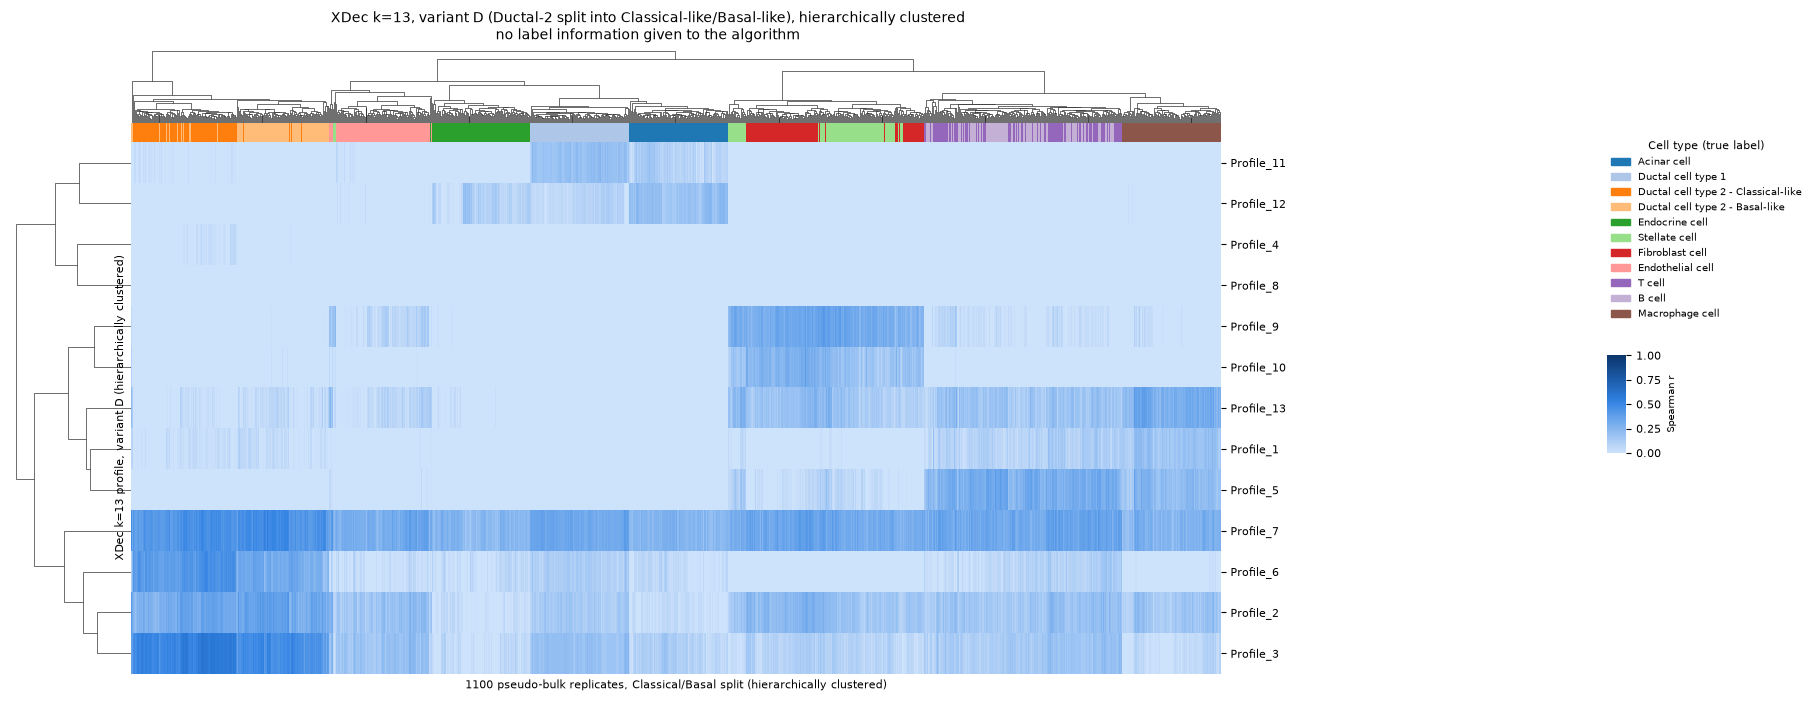

saved xdec_autotuned_n150/dead_profile_analysis/fig11_classicalBasal_profile_CLUSTERED.png


In [7]:
cell_palette_d = dict(zip(cell_type_order_d, sns.color_palette("tab20", len(cell_type_order_d))))

grid = sns.clustermap(
    corr_d, row_cluster=True, col_cluster=True, metric="euclidean", method="average",
    col_colors=pb_types_d.loc[pb_order_d].map(cell_palette_d).to_numpy(),
    cmap=seq_blue, vmin=0.0, vmax=1.0,
    xticklabels=False, yticklabels=True, figsize=(13, 6.5),
    cbar_kws={"label": "Spearman r", "ticks": [0, 0.25, 0.5, 0.75, 1]}, dendrogram_ratio=(0.10, 0.12),
)
grid.ax_heatmap.set_xlabel(f"{len(pb_order_d)} pseudo-bulk replicates, Classical/Basal split (hierarchically clustered)")
grid.ax_heatmap.set_ylabel("XDec k=13 profile, variant D (hierarchically clustered)")
grid.ax_heatmap.yaxis.set_label_position("left")
grid.ax_heatmap.tick_params(axis="y", rotation=0)

handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette_d[t]) for t in cell_type_order_d]
legend = grid.ax_heatmap.legend(
    handles, cell_type_order_d, title="Cell type (true label)", bbox_to_anchor=(1.35, 1.02),
    loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
)
grid.fig.suptitle("XDec k=13, variant D (Ductal-2 split into Classical-like/Basal-like), hierarchically clustered\n"
                   "no label information given to the algorithm", y=1.04, fontsize=10)
grid.fig.canvas.draw()
bbox = legend.get_window_extent(grid.fig.canvas.get_renderer()).transformed(grid.fig.transFigure.inverted())
grid.cax.set_position([bbox.x0, bbox.y0 - 0.20, 0.015, 0.15])
grid.cax.yaxis.label.set_fontsize(7)

fig_path_d = out_dir / "fig11_classicalBasal_profile_CLUSTERED.png"
grid.savefig(fig_path_d, dpi=200, bbox_inches="tight")
corr_d.to_csv(fig_path_d.with_suffix(".tsv"), sep="\t")
plt.show()
plt.close(grid.fig)
print("saved", fig_path_d)


**Interpretation (updated against the actual rendered figure and type-averaged correlations)**

* **Column side confirms the split is real**: `Ductal cell type 2 - Classical-like` and `- Basal-like` cluster as the two leftmost, adjacent-but-distinct column blocks in the dendrogram — separate from each other, and both separate from `Ductal cell type 1` (normal). The reference itself preserves a genuine three-way distinction (normal ductal vs. Classical-like malignant vs. Basal-like malignant) under fully unsupervised clustering, with no label input.
* **Row side confirms the model does NOT preserve that split**: averaging each profile's correlation across all replicates of a type, `Profile_3` is the clear maximum for *both* subtypes at once (Classical-like r=0.54, Basal-like r=0.46) — not specific to one. The next-nearest profiles (`Profile_6`: 0.42/0.31; `Profile_2`: 0.31/0.35) show the same pattern: elevated against both subtypes together, never selectively against just one. No profile among the 13 shows a clean "high vs. Classical-like, near-zero vs. Basal-like" (or the reverse) signature — the two-cancer-profile split the paper reports is simply absent from this fit.
* **`Profile_3` is still somewhat broad, not laser-specific**: besides Ductal-2, it also correlates moderately with Ductal cell type 1 (0.19), Endothelial (0.18), and T cell (0.16) — all well below the 0.46-0.54 seen for the two malignant subtypes, but non-trivial. The malignant signal dominates `Profile_3`, just not purely.
* **`Profile_4` and `Profile_8` are the visually blank rows** — `Profile_4` is the top dead profile from the numeric table above (78/150 samples dominant, all correlations near zero or negative); `Profile_8` is negatively correlated with almost everything.
* **Net reading**: this is the cleanest demonstration yet that the bottleneck is model-side, not reference-side. This reference variant contains the exact three-way ductal distinction the paper's result structure implies, and unsupervised clustering on the correlation matrix alone recovers that three-way split on the column side with no label input. XDec's NMF fit at k=13 still produces a single profile that answers to both malignant subtypes almost equally — confirming, independently of all three earlier variants, that giving the model better reference resolution does not translate into the model discovering or preserving that resolution.
